# 05 Tree Models and Hyperparameter Tuning

In [1]:
import json
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, f1_score, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline

PROCESSED = Path("../data/processed")
MODELS = Path("../models")
RESULTS = Path("../results")
FIG = RESULTS / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
spec = json.loads((MODELS / "features.json").read_text())
FEATURES, CATEGORICAL, GROUPS = spec["features"], spec["categorical"], spec["groups"]

X_train = pd.read_parquet(PROCESSED / "X_train.parquet")[FEATURES]
X_val = pd.read_parquet(PROCESSED / "X_val.parquet")[FEATURES]
y_train = pd.read_parquet(PROCESSED / "y_train.parquet").is_churn.values
y_val = pd.read_parquet(PROCESSED / "y_val.parquet").is_churn.values

val_rows = pd.read_csv(RESULTS / "validation_baselines.csv").to_dict(orient="records")
def record(name, p):
    row = {"model": name, "pr_auc": average_precision_score(y_val, p), "roc_auc": roc_auc_score(y_val, p),
           "log_loss": log_loss(y_val, np.clip(p, 1e-6, 1 - 1e-6)), "f1@0.5": f1_score(y_val, p >= 0.5)}
    val_rows.append(row)
    print({k: (round(v, 4) if k != "model" else v) for k, v in row.items()})

## Random Forest Tuning

In [2]:
forest_tuning, best_ll = [], np.inf
for leaf, feats in [(5, "sqrt"), (20, "sqrt"), (50, "sqrt"), (20, 0.5)]:
    m = make_pipeline(SimpleImputer(strategy="median"),
                      RandomForestClassifier(n_estimators=150, min_samples_leaf=leaf, max_features=feats,
                                             n_jobs=-1, random_state=42)).fit(X_train, y_train)
    ll = log_loss(y_val, m.predict_proba(X_val)[:, 1])
    forest_tuning.append({"min_samples_leaf": leaf, "max_features": feats, "val_log_loss": ll})
    print(f"min_samples_leaf={leaf:<3} max_features={feats!s:<5} validation log loss {ll:.5f}")
    if ll < best_ll:
        best_ll, forest = ll, m
record("Random forest", forest.predict_proba(X_val)[:, 1])

min_samples_leaf=5   max_features=sqrt  validation log loss 0.05557


min_samples_leaf=20  max_features=sqrt  validation log loss 0.05778


min_samples_leaf=50  max_features=sqrt  validation log loss 0.06062


min_samples_leaf=20  max_features=0.5   validation log loss 0.04660


{'model': 'Random forest', 'pr_auc': 0.9641, 'roc_auc': 0.9951, 'log_loss': 0.0461, 'f1@0.5': 0.9013}


## LightGBM Default

In [3]:
def fit_lgbm(params, cols=FEATURES):
    model = lgb.LGBMClassifier(n_estimators=2000, random_state=42, verbose=-1, n_jobs=-1, **params)
    model.fit(X_train[cols], y_train, eval_X=(X_val[cols],), eval_y=(y_val,),
              categorical_feature=[c for c in CATEGORICAL if c in cols],
              callbacks=[lgb.early_stopping(50, verbose=False)])  # number of trees chosen on validation
    return model

lgbm_default = fit_lgbm({"learning_rate": 0.05})
record("LightGBM (default)", lgbm_default.predict_proba(X_val)[:, 1])
print("trees used:", lgbm_default.best_iteration_)

{'model': 'LightGBM (default)', 'pr_auc': 0.967, 'roc_auc': 0.9957, 'log_loss': 0.0439, 'f1@0.5': 0.9035}
trees used: 697


## LightGBM Tuning with Optuna

best validation log loss 0.04232 {'learning_rate': 0.06691081028876568, 'num_leaves': 50, 'min_child_samples': 20, 'subsample': 0.998406612698974, 'colsample_bytree': 0.8905895135405482, 'reg_lambda': 0.12208736097730166, 'subsample_freq': 1}


{'model': 'LightGBM (tuned)', 'pr_auc': 0.9686, 'roc_auc': 0.9962, 'log_loss': 0.0423, 'f1@0.5': 0.9064}
trees used: 861


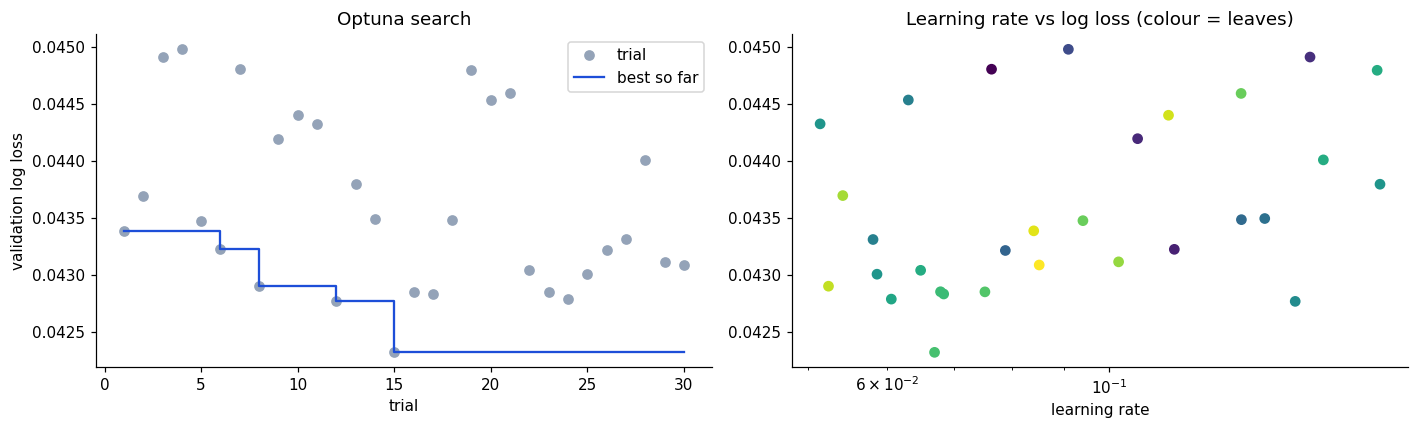

In [4]:
def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.05, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 63),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 400, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0), "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    return log_loss(y_val, fit_lgbm(params).predict_proba(X_val)[:, 1])

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30)
best_params = {**study.best_params, "subsample_freq": 1}
print("best validation log loss", round(study.best_value, 5), best_params)

champion = fit_lgbm(best_params)
record("LightGBM (tuned)", champion.predict_proba(X_val)[:, 1])
print("trees used:", champion.best_iteration_)

trials = study.trials_dataframe()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(trials.number + 1, trials.value, "o", color="#94A3B8", label="trial")
ax[0].step(trials.number + 1, trials.value.cummin(), where="post", color="#1D4ED8", label="best so far")
ax[0].set(title="Optuna search", xlabel="trial", ylabel="validation log loss"); ax[0].legend()
ax[1].scatter(trials.params_learning_rate, trials.value, c=trials.params_num_leaves, cmap="viridis")
ax[1].set(title="Learning rate vs log loss (colour = leaves)", xlabel="learning rate", xscale="log")
plt.tight_layout(); plt.savefig(FIG / "tuning_optuna.png"); plt.show()

## Validation Comparison

In [5]:
val_table = pd.DataFrame(val_rows).set_index("model").round(4)
val_table.to_csv(RESULTS / "validation_metrics.csv")
val_table

,pr_auc,roc_auc,log_loss,f1@0.5
model,,,,
Majority (prior),0.0899,0.5000,0.3024,0.0000
Rule: auto-renew off,0.3162,0.7744,0.2287,0.0000
Logistic regression,0.8991,0.9760,0.0854,0.8512
Random forest,0.9641,0.9951,0.0461,0.9013
LightGBM (default),0.9670,0.9957,0.0439,0.9035
LightGBM (tuned),0.9686,0.9962,0.0423,0.9064


## Decision Threshold

In [6]:
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
p_val = champion.predict_proba(X_val)[:, 1]
f1s = [f1_score(y_val, p_val >= t) for t in grid]
tau = float(grid[int(np.argmax(f1s))])
print(f"chosen threshold tau = {tau:.2f} (validation F1 {max(f1s):.4f})")

chosen threshold tau = 0.45 (validation F1 0.9081)


## Feature Set Ablation

In [7]:
SETS = {"Billing + demographics": GROUPS["demographic"] + GROUPS["billing"],
        "Listening + demographics": GROUPS["demographic"] + GROUPS["listening"],
        "All features": FEATURES}
ablation = {}
for name, cols in SETS.items():
    ablation[name] = fit_lgbm(best_params, cols)
    p = ablation[name].predict_proba(X_val[cols])[:, 1]
    print(f"{name:26s} validation PR-AUC {average_precision_score(y_val, p):.4f} | log loss {log_loss(y_val, p):.4f}")

Billing + demographics     validation PR-AUC 0.9599 | log loss 0.0459


Listening + demographics   validation PR-AUC 0.4107 | log loss 0.2367


All features               validation PR-AUC 0.9686 | log loss 0.0423


## Save

In [8]:
joblib.dump(forest, MODELS / "random_forest.joblib", compress=3)
lgbm_default.booster_.save_model(MODELS / "lgbm_default.txt")
champion.booster_.save_model(MODELS / "lgbm_champion.txt")
for name, m in ablation.items():
    m.booster_.save_model(MODELS / f"lgbm_ablation_{name.split()[0].lower()}.txt")

config = {**spec, "best_params": best_params, "n_trees": int(champion.best_iteration_), "threshold": tau,
          "ablation_sets": SETS,
          "tuning": {"logreg": json.loads((RESULTS / "tuning_logreg.json").read_text()), "forest": forest_tuning},
          "optuna_trials": [{"n": t.number, "log_loss": t.value, **t.params} for t in study.trials]}
(MODELS / "model_config.json").write_text(json.dumps(config, indent=1))
print("saved models and results/validation_metrics.csv")

saved models and results/validation_metrics.csv
